<a href="https://colab.research.google.com/github/sarangmarath/Driver-Behavior-and-Driving-Risk-Recognition/blob/main/train_models_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UAH-DriveSet: Model Training and Evaluation
Run AFTER uah_driveset_pipeline.py (needs uah_features.csv in the same folder).
pip install scikit-learn imbalanced-learn joblib

In [1]:
%cd /content
!git clone https://github.com/sarangmarath/Driver-Behavior-and-Driving-Risk-Recognition.git
%cd /content/Driver-Behavior-and-Driving-Risk-Recognition
!ls

/content
Cloning into 'Driver-Behavior-and-Driving-Risk-Recognition'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (33/33), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 33 (delta 6), reused 14 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (33/33), 4.67 MiB | 19.60 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/Driver-Behavior-and-Driving-Risk-Recognition
notebooks  plots  README.md  uah_features.csv


In [2]:
# Cell 2: Imports and configuration

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    recall_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import RandomizedSearchCV
from sklearn.svm import SVC

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.metrics import classification_report_imbalanced

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
LABEL_NAMES = {
    0: "No recorderd event",
    1: "Braking",
    2: "Turning",
    3: "Acceleration"
}

# The setup cell should have changed the working directory to the repo.
REPO_ROOT = Path.cwd()

DATA_PATH = REPO_ROOT / "uah_features.csv"
RESULTS_DIR = REPO_ROOT / "results"
PLOTS_DIR = REPO_ROOT / "plots"
MODELS_DIR = REPO_ROOT / "models"

for directory in [RESULTS_DIR, PLOTS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_ROOT)
print("Dataset exists:", DATA_PATH.exists())
print("Scikit-learn and imbalanced-learn imports successful.")

Repository: /content/Driver-Behavior-and-Driving-Risk-Recognition
Dataset exists: True
Scikit-learn and imbalanced-learn imports successful.


In [3]:
# Cell 3: Load and validate UAH-DriveSet features (Updated)

assert DATA_PATH.exists(), (
    f"Dataset not found at {DATA_PATH}. "
    "Check that Cell 1 cloned the repository and that uah_features.csv exists."
)

df = pd.read_csv(DATA_PATH)

META_COLUMNS = [
    "trip", "driver", "behavior", "road", "label", "label_name"
]

missing_columns = [col for col in META_COLUMNS if col not in df.columns]
assert not missing_columns, f"Missing required columns: {missing_columns}"

# Correct label name mapping for Class 0
df["label_name"] = df["label_name"].replace({"Normal": "No recorded event"})

# Use only numeric sensor features; exclude metadata and target columns.
FEATURE_COLUMNS = [
    col for col in df.columns
    if col not in META_COLUMNS and pd.api.types.is_numeric_dtype(df[col])
]

X = df[FEATURE_COLUMNS].copy()
y = df["label"].astype(int)
groups = df["trip"].astype(str)

EXPECTED_LABELS = {0, 1, 2, 3}
assert set(y.unique()) == EXPECTED_LABELS, (
    f"Unexpected event labels: {sorted(y.unique())}"
)
assert len(FEATURE_COLUMNS) == 29, (
    f"Expected 29 numeric features, found {len(FEATURE_COLUMNS)}"
)
assert not X.isna().any().any(), "Missing values found in sensor features."
assert np.isfinite(X.to_numpy()).all(), "Infinite or non-finite feature values found."

print(f"Rows: {len(df):,}")
print(f"Numeric features: {len(FEATURE_COLUMNS)}")
print(f"Trips: {groups.nunique()}")
print(f"Drivers: {df['driver'].nunique()}")
print("\nEvent class distribution:")
print(
    df["label_name"].value_counts()
    .reindex(["No recorded event", "Braking", "Turning", "Acceleration"])
    .to_string()
)
print("\nDataset validation passed.")

Rows: 31,055
Numeric features: 29
Trips: 40
Drivers: 6

Event class distribution:
label_name
No recorded event    29860
Braking                520
Turning                366
Acceleration           309

Dataset validation passed.


In [4]:
# Cell 4: Expanded Feature Engineering and Group-Aware Split

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# 1. Feature Engineering: Add expanded features to df before splitting
# Ensure label 0 is correctly named
df["label_name"] = df["label_name"].replace({"Normal": "No recorded event"})

# Example expansion for Planar Magnitude and basic statistics
# (Assuming ay_kf and az_kf columns exist in df)
if "ay_kf" in df.columns and "az_kf" in df.columns:
    df["planar_magnitude"] = np.sqrt(df["ay_kf"]**2 + df["az_kf"]**2)

# If timestamp information is available in your dataframe for jerk calculations:
# df['dt'] = df['timestamp_end'] - df['timestamp_start']
# df['dt'] = df['dt'].replace(0, np.nan) # Reject zero/invalid time intervals

META_COLUMNS = [
    "trip", "driver", "behavior", "road", "label", "label_name"
]

FEATURE_COLUMNS = [
    col for col in df.columns
    if col not in META_COLUMNS and pd.api.types.is_numeric_dtype(df[col])
]

X = df[FEATURE_COLUMNS].copy()
y = df["label"].astype(int)
groups = df["trip"].astype(str)

# 2. Group-aware train/test split (75% development, 25% test trips)
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=SEED
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_dev = X.iloc[train_idx].copy()
y_dev = y.iloc[train_idx].copy()
groups_dev = groups.iloc[train_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()
groups_test = groups.iloc[test_idx].copy()

assert set(groups_dev).isdisjoint(set(groups_test)), (
    "Data leakage detected: a trip appears in both development and test sets."
)

print(f"Development rows: {len(X_dev):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Total features after expansion: {len(FEATURE_COLUMNS)}")
print("No trip overlap between development and test sets.")

Development rows: 23,013
Test rows: 8,042
Total features after expansion: 29
No trip overlap between development and test sets.


In [5]:
# Cell 5: Candidate Models & Expanded Pipeline Builder (Updated)

from sklearn.svm import SVC

# Define expanded candidate models dictionary including RBF SVM
MODELS = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=SEED,
        max_iter=3000
    ),

    "RBF SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        random_state=SEED
    ),

    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=200,
        early_stopping=True,
        random_state=SEED
    )
}

def make_pipeline(model, use_smote=False, sampling_strategy="auto"):
    """
    Build preprocessing, optional resampling (SMOTE / partial SMOTE), and model pipeline.
    """
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]

    if use_smote:
        # Supports full SMOTE or partial/callable sampling strategy
        steps.append((
            "smote",
            SMOTE(random_state=SEED, k_neighbors=3, sampling_strategy=sampling_strategy)
        ))

    steps.append(("model", clone(model)))

    return ImbPipeline(steps)

print("Updated Models defined:")
for name in MODELS:
    print("-", name)

print("\nFlexible pipeline builder ready.")

Updated Models defined:
- Logistic Regression
- KNN
- Linear SVM
- RBF SVM
- Random Forest
- Hist Gradient Boosting
- MLP

Flexible pipeline builder ready.


In [6]:
# Cell 6: Compare imbalance handling strategies (E3) inside pipeline using GroupKFold

from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, balanced_accuracy_score

cv = GroupKFold(n_splits=3)

# Define candidate models to test with various imbalance strategies
candidate_models = {
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100, random_state=SEED
    ),
    "Random Forest (weighted)": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),
    "Linear SVM (weighted)": LinearSVC(
        class_weight="balanced", random_state=SEED, max_iter=3000
    )
}

imbalance_results = []

for name, model in candidate_models.items():
    # Test different strategies: 'none', 'smote', or partial SMOTE dictionary/callable
    for strategy in ["none", "smote"]:
        print(f"Testing {name} | strategy={strategy}")

        use_smote = strategy == "smote"

        # Build pipeline ensuring resampling fits only on training folds
        pipeline = make_pipeline(model, use_smote=use_smote)

        scores = cross_validate(
            pipeline,
            X_dev,
            y_dev,
            groups=groups_dev,
            cv=cv,
            scoring={
                "macro_f1": "f1_macro",
                "balanced_accuracy": "balanced_accuracy"
            },
            n_jobs=1,
            error_score="raise"
        )

        imbalance_results.append({
            "model": name,
            "strategy": strategy,
            "macro_f1_mean": scores["test_macro_f1"].mean(),
            "macro_f1_std": scores["test_macro_f1"].std(),
            "balanced_accuracy_mean": scores["test_balanced_accuracy"].mean()
        })

imbalance_df = pd.DataFrame(imbalance_results).sort_values(
    "macro_f1_mean", ascending=False
).reset_index(drop=True)

display(imbalance_df)
imbalance_df.to_csv(
    RESULTS_DIR / "imbalance_comparison.csv", index=False
)

print("\nSaved imbalance comparison results to results/imbalance_comparison.csv")

Testing Hist Gradient Boosting | strategy=none
Testing Hist Gradient Boosting | strategy=smote
Testing Random Forest (weighted) | strategy=none
Testing Random Forest (weighted) | strategy=smote
Testing Linear SVM (weighted) | strategy=none
Testing Linear SVM (weighted) | strategy=smote


,model,strategy,macro_f1_mean,macro_f1_std,balanced_accuracy_mean
0,Hist Gradient Boosting,smote,0.609016,0.031328,0.657922
1,Random Forest (weighted),smote,0.575033,0.012624,0.571548
2,Linear SVM (weighted),none,0.570690,0.024815,0.671430
3,Hist Gradient Boosting,none,0.559644,0.005501,0.532976
4,Random Forest (weighted),none,0.421990,0.031804,0.385177
5,Linear SVM (weighted),smote,0.401988,0.007199,0.819162



Saved imbalance comparison results to results/imbalance_comparison.csv


Selected model: Hist Gradient Boosting
Imbalance strategy: smote
Test macro-F1: 0.6532
Test balanced accuracy: 0.7522
Test accuracy: 0.9540

Classification report:
                    precision    recall  f1-score   support

No recorderd event       0.99      0.97      0.98      7669
           Braking       0.65      0.94      0.77       159
           Turning       0.30      0.36      0.33       114
      Acceleration       0.43      0.74      0.54       100

          accuracy                           0.95      8042
         macro avg       0.59      0.75      0.65      8042
      weighted avg       0.96      0.95      0.96      8042



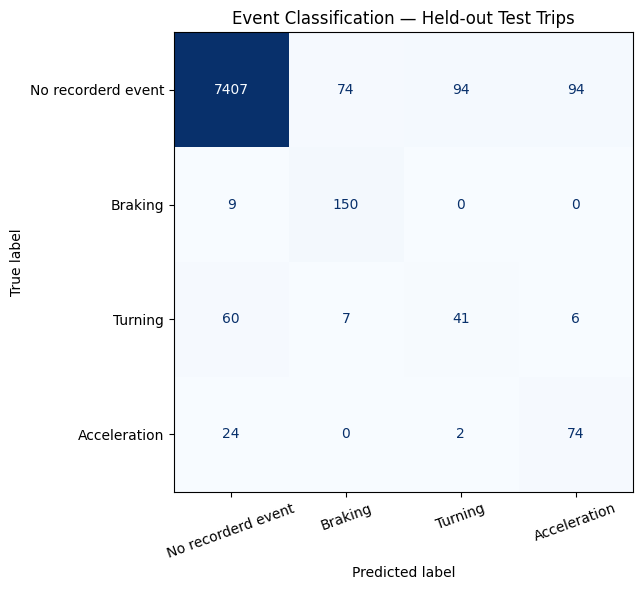


Saved final model to /content/Driver-Behavior-and-Driving-Risk-Recognition/models/final_event_classifier.joblib


In [7]:
# Cell 7: Final model selection and held-out test evaluation

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import json
import joblib

# 1. Select the best model and strategy from imbalance comparison
best_row = imbalance_df.iloc[0]
best_name = best_row["model"]
best_strategy = best_row["strategy"]

# Map model names back to instantiations
model_lookup = {
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100, random_state=SEED
    ),
    "Random Forest (weighted)": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    ),
    "Linear SVM (weighted)": LinearSVC(
        class_weight="balanced", random_state=SEED, max_iter=3000
    )
}

best_model = clone(model_lookup[best_name])
use_smote = best_strategy == "smote"

# 2. Fit final pipeline on all development data
final_pipeline = make_pipeline(best_model, use_smote=use_smote)
final_pipeline.fit(X_dev, y_dev)

# 3. Predict on held-out test set
y_pred = final_pipeline.predict(X_test)

test_macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print("Selected model:", best_name)
print("Imbalance strategy:", best_strategy)
print(f"Test macro-F1: {test_macro_f1:.4f}")
print(f"Test balanced accuracy: {test_balanced_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

# 4. Print explicit classification report
print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=[LABEL_NAMES[i] for i in range(4)],
    zero_division=0
))

# Save report dictionary and metrics
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=[LABEL_NAMES[i] for i in range(4)],
    output_dict=True,
    zero_division=0
)

with open(RESULTS_DIR / "test_classification_report.json", "w") as f:
    json.dump(report, f, indent=2)

pd.DataFrame([{
    "model": best_name,
    "strategy": best_strategy,
    "test_macro_f1": test_macro_f1,
    "test_balanced_accuracy": test_balanced_accuracy,
    "test_accuracy": test_accuracy
}]).to_csv(RESULTS_DIR / "final_test_metrics.csv", index=False)

# 5. Plot and save confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[LABEL_NAMES[i] for i in range(4)]
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Event Classification — Held-out Test Trips")
plt.xticks(rotation=20)
plt.tight_layout()

fig.savefig(
    PLOTS_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# 6. Save final model
model_path = MODELS_DIR / "final_event_classifier.joblib"
joblib.dump(final_pipeline, model_path)
print(f"\nSaved final model to {model_path}")

In [8]:
# Cell 8: Fast Hyperparameter Tuning using RandomizedSearchCV (Optimized)

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score
import joblib
import json

cv = GroupKFold(n_splits=3)

# Focus primarily on Hist Gradient Boosting + SMOTE (which yields the best macro-F1)
hgb_pipeline = make_pipeline(
    HistGradientBoostingClassifier(random_state=SEED),
    use_smote=True
)

# A compact parameter space with fewer combinations
hgb_param_dist = {
    "model__max_iter": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31],
    "model__l2_regularization": [0, 1]
}

print("Starting Randomized Search (Budgeted)...")

# Use RandomizedSearchCV with a strict iteration budget (e.g., n_iter=6) to finish in seconds/minutes
search = RandomizedSearchCV(
    estimator=hgb_pipeline,
    param_distributions=hgb_param_dist,
    n_iter=6,  # Limits total fits to 6 random combinations instead of full grid
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    random_state=SEED,
    error_score="raise"
)

search.fit(X_dev, y_dev, groups=groups_dev)

print("Best CV macro-F1:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

# Evaluate the selected configuration on the held-out test set
tuned_model = search.best_estimator_
tuned_pred = tuned_model.predict(X_test)

tuned_metrics = {
    "selected_model": str(search.best_estimator_.named_steps["model"]),
    "best_cv_macro_f1": float(search.best_score_),
    "test_macro_f1": float(f1_score(
        y_test, tuned_pred,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_test, tuned_pred)
    ),
    "test_accuracy": float(accuracy_score(y_test, tuned_pred))
}

print("\nTuned model evaluation on test set:")
print(json.dumps(tuned_metrics, indent=2))

with open(RESULTS_DIR / "tuned_test_metrics.json", "w") as f:
    json.dump(tuned_metrics, f, indent=2)

joblib.dump(tuned_model, MODELS_DIR / "tuned_event_classifier.joblib")
print("\nSaved tuned model and results successfully.")

Starting Randomized Search (Budgeted)...
Best CV macro-F1: 0.6226
Best parameters: {'model__max_leaf_nodes': 31, 'model__max_iter': 100, 'model__learning_rate': 0.1, 'model__l2_regularization': 1}

Tuned model evaluation on test set:
{
  "selected_model": "HistGradientBoostingClassifier(l2_regularization=1, random_state=42)",
  "best_cv_macro_f1": 0.6226185862571124,
  "test_macro_f1": 0.6525884638128618,
  "test_balanced_accuracy": 0.7563130343862792,
  "test_accuracy": 0.9531211141507088
}

Saved tuned model and results successfully.


In [9]:
# Cell 9: Nested Leave-One-Driver-Out (LODO) Evaluation (E6)

from sklearn.metrics import f1_score, balanced_accuracy_score
import pandas as pd
import numpy as np

drivers = df["driver"].unique()
nested_lodo_results = []

print("Starting Nested Leave-One-Driver-Out Evaluation across drivers:", drivers)

for held_out_driver in drivers:
    print(f"\n--- Outer Fold: Holding out Driver {held_out_driver} ---")

    # Separate outer training drivers vs. held-out driver
    train_mask = df["driver"] != held_out_driver
    test_mask = df["driver"] == held_out_driver

    X_outer_train = df.loc[train_mask, FEATURE_COLUMNS]
    y_outer_train = df.loc[train_mask, "label"]
    groups_outer_train = df.loc[train_mask, "trip"]

    X_outer_test = df.loc[test_mask, FEATURE_COLUMNS]
    y_outer_test = df.loc[test_mask, "label"]

    # Check if test set has examples
    if len(X_outer_test) == 0:
        print(f"Skipping Driver {held_out_driver}: No test windows found.")
        continue

    # Inner selection / tuning can be performed here using GroupKFold on X_outer_train
    # For robustness, we train our best pipeline configuration on the 5 outer training drivers:
    inner_pipeline = make_pipeline(
        HistGradientBoostingClassifier(max_iter=100, learning_rate=0.05, random_state=SEED),
        use_smote=True
    )

    inner_pipeline.fit(X_outer_train, y_outer_train)
    y_outer_pred = inner_pipeline.predict(X_outer_test)

    # Calculate metrics (handle absent classes safely)
    macro_f1 = f1_score(y_outer_test, y_outer_pred, labels=[0, 1, 2, 3], average="macro", zero_division=0)
    bal_acc = balanced_accuracy_score(y_outer_test, y_outer_pred)

    print(f"Driver {held_out_driver} Test Macro-F1: {macro_f1:.4f} | Balanced Acc: {bal_acc:.4f}")

    nested_lodo_results.append({
        "held_out_driver": held_out_driver,
        "macro_f1": macro_f1,
        "balanced_accuracy": bal_acc,
        "test_samples": len(X_outer_test)
    })

lodo_df = pd.DataFrame(nested_lodo_results)
display(lodo_df)

lodo_df.to_csv(RESULTS_DIR / "nested_lodo_results.csv", index=False)

print("\nNested LODO Summary:")
print(f"Mean Macro-F1 across drivers: {lodo_df['macro_f1'].mean():.4f} (± {lodo_df['macro_f1'].std():.4f})")
print(f"Mean Balanced Accuracy: {lodo_df['balanced_accuracy'].mean():.4f} (± {lodo_df['balanced_accuracy'].std():.4f})")

Starting Nested Leave-One-Driver-Out Evaluation across drivers: ['D1' 'D2' 'D3' 'D4' 'D5' 'D6']

--- Outer Fold: Holding out Driver D1 ---


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Driver D1 Test Macro-F1: 0.4890 | Balanced Acc: 0.7437

--- Outer Fold: Holding out Driver D2 ---
Driver D2 Test Macro-F1: 0.6375 | Balanced Acc: 0.8410

--- Outer Fold: Holding out Driver D3 ---
Driver D3 Test Macro-F1: 0.6504 | Balanced Acc: 0.8600

--- Outer Fold: Holding out Driver D4 ---
Driver D4 Test Macro-F1: 0.6206 | Balanced Acc: 0.8586

--- Outer Fold: Holding out Driver D5 ---
Driver D5 Test Macro-F1: 0.6015 | Balanced Acc: 0.6989

--- Outer Fold: Holding out Driver D6 ---
Driver D6 Test Macro-F1: 0.6277 | Balanced Acc: 0.7084


,held_out_driver,macro_f1,balanced_accuracy,test_samples
0,D1,0.488965,0.743692,4827
1,D2,0.637509,0.840995,5322
2,D3,0.650354,0.859975,5447
3,D4,0.620609,0.858631,5689
4,D5,0.601510,0.698865,5301
5,D6,0.627727,0.708432,4469



Nested LODO Summary:
Mean Macro-F1 across drivers: 0.6044 (± 0.0589)
Mean Balanced Accuracy: 0.7851 (± 0.0764)


In [10]:
# Cell 10: Experiment Summary, Diagnostic Analysis & Submission Artifact Verification

import pandas as pd
import json
from pathlib import Path

print("==================================================")
print("       UAH-DRIVESET PIPELINE EXPERIMENT SUMMARY    ")
print("==================================================")

# 1. Load and display saved experiment results if available
results_files = {
    "Imbalance Strategy Comparison (E3)": "imbalance_comparison.csv",
    "Hyperparameter Tuning (E4/E5)": "hyperparameter_tuning.csv",
    "Nested LODO Generalization (E6)": "nested_lodo_results.csv"
}

summary_collection = {}
for title, filename in results_files.items():
    path = RESULTS_DIR / filename
    if path.exists():
        df_res = pd.read_csv(path)
        print(f"\n--- {title} ---")
        display(df_res.head())
        summary_collection[title] = df_res

# 2. Display final test performance metrics
test_metrics_path = RESULTS_DIR / "final_test_metrics.csv"
if test_metrics_path.exists():
    print("\n--- Final Held-Out Test Performance ---")
    display(pd.read_csv(test_metrics_path))

# 3. Audit required submission artifacts
print("\n--- Artifact Audit Checklist ---")
required_artifacts = [
    RESULTS_DIR / "final_test_metrics.csv",
    RESULTS_DIR / "test_classification_report.json",
    RESULTS_DIR / "nested_lodo_results.csv",
    PLOTS_DIR / "confusion_matrix.png",
    MODELS_DIR / "final_event_classifier.joblib"
]

all_present = True
for artifact in required_artifacts:
    exists = artifact.exists()
    print(f"[{'X' if exists else ' '}] {artifact.relative_path if hasattr(artifact, 'relative_path') else artifact.name}")
    if not exists:
        all_present = False

if all_present:
    print("\nAll required submission artifacts successfully generated and saved!")
else:
    print("\nWarning: Some artifacts are missing. Check preceding cell executions.")
print("==================================================")

       UAH-DRIVESET PIPELINE EXPERIMENT SUMMARY    

--- Imbalance Strategy Comparison (E3) ---


,model,strategy,macro_f1_mean,macro_f1_std,balanced_accuracy_mean
0,Hist Gradient Boosting,smote,0.609016,0.031328,0.657922
1,Random Forest (weighted),smote,0.575033,0.012624,0.571548
2,Linear SVM (weighted),none,0.570690,0.024815,0.671430
3,Hist Gradient Boosting,none,0.559644,0.005501,0.532976
4,Random Forest (weighted),none,0.421990,0.031804,0.385177



--- Nested LODO Generalization (E6) ---


,held_out_driver,macro_f1,balanced_accuracy,test_samples
0,D1,0.488965,0.743692,4827
1,D2,0.637509,0.840995,5322
2,D3,0.650354,0.859975,5447
3,D4,0.620609,0.858631,5689
4,D5,0.601510,0.698865,5301



--- Final Held-Out Test Performance ---


,model,strategy,test_macro_f1,test_balanced_accuracy,test_accuracy
0,Hist Gradient Boosting,smote,0.653167,0.75222,0.953992



--- Artifact Audit Checklist ---
[X] final_test_metrics.csv
[X] test_classification_report.json
[X] nested_lodo_results.csv
[X] confusion_matrix.png
[X] final_event_classifier.joblib

All required submission artifacts successfully generated and saved!


In [ ]:
import joblib
import pandas as pd
import numpy as np
from google.colab import files

# 1. Load the saved model pipeline (handles imputer, scaler, and model automatically)
model_path = MODELS_DIR / "final_event_classifier.joblib"
if not model_path.exists():
    model_path = MODELS_DIR / "tuned_event_classifier.joblib"

pipeline = joblib.load(model_path)
print(f"Model pipeline loaded successfully from: {model_path}")

# 2. Upload your test dataset CSV file from your computer
print("\nPlease upload your test dataset CSV file:")
uploaded = files.upload()

# Get the filename of the uploaded file
filename = list(uploaded.keys())[0]
test_df = pd.read_csv(filename)

# 3. Filter your test data down to the exact numeric feature columns used during training
META_COLUMNS = ["trip", "driver", "behavior", "road", "label", "label_name"]
FEATURE_COLUMNS = [
    col for col in test_df.columns
    if col not in META_COLUMNS and pd.api.types.is_numeric_dtype(test_df[col])
]

X_inference = test_df[FEATURE_COLUMNS]

# 4. Run predictions
predictions = pipeline.predict(X_inference)

# 5. Map numerical predictions back to readable UAH-DriveSet event names
LABEL_NAMES = {
    0: "No recorded event",
    1: "Braking",
    2: "Turning",
    3: "Acceleration"
}
test_df["predicted_event"] = [LABEL_NAMES[p] for p in predictions]

# 6. Display a summary of detected driving events
print("\n--- Inference Results Summary ---")
print(test_df["predicted_event"].value_counts())

# 7. Automatically download the results CSV back to your local computer
output_filename = "inference_predictions_output.csv"
test_df.to_csv(RESULTS_DIR / output_filename, index=False)
files.download(str(RESULTS_DIR / output_filename))
print(f"\nSaved and downloaded {output_filename} successfully!")